### Part 1: Initial Weather Data Retrieval and Synchronization
This section loads the landslide dataset, drops duplicated space-time coordinates, and queries NASA's POWER API to fetch consistent dynamic rainfall features (1-day, 3-day, 7-day, 14-day, and 30-day accumulation, max daily rain, and number of rainfall days) for each record.

In [5]:
import time, requests, numpy as np, pandas as pd

RAIN_COLS = ["rain_1d_mm","rain_3d_mm","rain_7d_mm","rain_14d_mm","rain_30d_mm","max_daily_rain_7d_mm","rainfall_days_7d"]
POWER_URL = "https://power.larc.nasa.gov/api/temporal/daily/point"

def power_features(lat, lon, date):
    date = pd.Timestamp(date)
    params = {"parameters": "PRECTOTCORR", "community": "AG", "longitude": float(lon), "latitude": float(lat),
              "start": (date - pd.Timedelta(days=29)).strftime("%Y%m%d"), "end": date.strftime("%Y%m%d"), "format": "JSON"}
    r = requests.get(POWER_URL, params=params, timeout=60); r.raise_for_status()
    s = pd.Series(r.json()["properties"]["parameter"]["PRECTOTCORR"], dtype="float64").replace(-999, np.nan).dropna()
    if len(s) < 30: raise ValueError(f"only {len(s)} days returned")
    return {"rain_1d_mm": s.iloc[-1], "rain_3d_mm": s.tail(3).sum(), "rain_7d_mm": s.tail(7).sum(),
            "rain_14d_mm": s.tail(14).sum(), "rain_30d_mm": s.tail(30).sum(),
            "max_daily_rain_7d_mm": s.tail(7).max(), "rainfall_days_7d": int((s.tail(7) > 0).sum())}

df = pd.read_csv("/content/data/landslide_dynamic_ml_dataset_terrain.csv", parse_dates=["event_date"])
jobs = df[["lat","lon","event_date"]].drop_duplicates().reset_index(drop=True)
print("API calls needed:", len(jobs))

rows = []
for i, r in jobs.iterrows():
    try:
        out = power_features(r.lat, r.lon, r.event_date); out["status"] = "ok"
    except Exception as e:
        out = {c: np.nan for c in RAIN_COLS}; out["status"] = f"failed: {e}"
    rows.append({"lat": r.lat, "lon": r.lon, "event_date": r.event_date, **out})
    if i % 100 == 0: print(i, "done")
    time.sleep(0.15)

new = pd.DataFrame(rows)
print(new.status.value_counts().to_dict())
fixed = df.drop(columns=RAIN_COLS).merge(new.drop(columns="status"), on=["lat","lon","event_date"],
                                         how="left", validate="many_to_one")
fixed.to_csv("landslide_dynamic_v2_consistent_rain.csv", index=False)
print(fixed.shape)

API calls needed: 958
0 done
100 done
200 done
300 done
400 done
500 done
600 done
700 done
800 done
900 done
{'ok': 715, 'failed: 429 Client Error: Too Many Requests for url: https://power.larc.nasa.gov/api/temporal/daily/point?parameters=PRECTOTCORR&community=AG&longitude=80.92489866&latitude=7.013973329&start=20251029&end=20251127&format=JSON': 1, 'failed: 429 Client Error: Too Many Requests for url: https://power.larc.nasa.gov/api/temporal/daily/point?parameters=PRECTOTCORR&community=AG&longitude=80.82920714&latitude=6.797900728&start=20251029&end=20251127&format=JSON': 1, 'failed: 429 Client Error: Too Many Requests for url: https://power.larc.nasa.gov/api/temporal/daily/point?parameters=PRECTOTCORR&community=AG&longitude=80.58117659&latitude=6.79753405&start=20251029&end=20251127&format=JSON': 1, 'failed: 429 Client Error: Too Many Requests for url: https://power.larc.nasa.gov/api/temporal/daily/point?parameters=PRECTOTCORR&community=AG&longitude=80.66192603&latitude=7.048397005&

### Part 2: Feature Importance Evaluation (Spatial Folds)
Evaluating single-feature predictive power using Area Under the ROC Curve (AUC) across spatial validation folds before fixing missing values.

In [6]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import roc_auc_score
y = fixed["dynamic_label"].values; folds = fixed["fold"].values
res = []
for f in RAIN_COLS:
    aucs = []
    for k in np.unique(folds):
        tr, te = folds != k, folds == k
        m = DecisionTreeClassifier(max_depth=3, random_state=42).fit(fixed.loc[tr, [f]].fillna(0), y[tr])
        aucs.append(roc_auc_score(y[te], m.predict_proba(fixed.loc[te, [f]].fillna(0))[:, 1]))
    res.append((f, round(np.mean(aucs), 3)))
print(pd.DataFrame(res, columns=["feature", "single_feature_AUC"]))

                feature  single_feature_AUC
0            rain_1d_mm               0.772
1            rain_3d_mm               0.768
2            rain_7d_mm               0.771
3           rain_14d_mm               0.773
4           rain_30d_mm               0.773
5  max_daily_rain_7d_mm               0.760
6      rainfall_days_7d               0.752


### Part 3: Identifying and Inspecting Missing API Records
Analyzing the proportion and target-label distribution of records affected by rate-limiting (HTTP 429 Errors) in the initial weather retrieval run.

In [7]:
print(new.status.str[:60].value_counts())
miss = fixed[RAIN_COLS].isna().any(axis=1)
print(pd.crosstab(fixed.dynamic_label, miss, rownames=["label"], colnames=["rain missing"]))

status
ok                                                              715
failed: 429 Client Error: Too Many Requests for url: https:/    243
Name: count, dtype: int64
rain missing  False  True 
label                     
0               236    243
1               479      0


### Part 4: Targeted API Retry Logic & Final Consistency Check
Resolving remaining weather records with exponential backoff retries to ensure a near-complete dataset with minimal data loss.

In [8]:
bad = new.index[new.status != "ok"]
print("retrying", len(bad))
for i in bad:
    r = new.loc[i]
    for attempt in range(5):
        try:
            out = power_features(r.lat, r.lon, r.event_date)
            for c in RAIN_COLS: new.loc[i, c] = out[c]
            new.loc[i, "status"] = "ok"; break
        except Exception as e:
            new.loc[i, "status"] = f"failed: {e}"; time.sleep(3 * (attempt + 1))
    time.sleep(0.3)
print(new.status.str[:60].value_counts())

retrying 243
status
ok                                                              956
failed: 429 Client Error: Too Many Requests for url: https:/      2
Name: count, dtype: int64


### Part 5: Model Evaluation on Complete Clean Dataset
Re-evaluating single-feature predictive performance on the fully synchronized and complete rows.

In [9]:
fixed = df.drop(columns=RAIN_COLS).merge(new.drop(columns="status"), on=["lat","lon","event_date"],
                                         how="left", validate="many_to_one")
print("rows still missing rain:", int(fixed[RAIN_COLS].isna().any(axis=1).sum()))
d = fixed[fixed[RAIN_COLS].notna().all(axis=1)].reset_index(drop=True)   # only complete rows
y = d["dynamic_label"].values; folds = d["fold"].values
res = []
for f in RAIN_COLS:
    aucs = []
    for k in np.unique(folds):
        tr, te = folds != k, folds == k
        if len(np.unique(y[te])) < 2: continue
        m = DecisionTreeClassifier(max_depth=3, random_state=42).fit(d.loc[tr, [f]], y[tr])
        aucs.append(roc_auc_score(y[te], m.predict_proba(d.loc[te, [f]])[:, 1]))
    res.append((f, round(np.mean(aucs), 3)))
print(len(d), "complete rows"); print(pd.DataFrame(res, columns=["feature", "single_feature_AUC"]))
fixed.to_csv("landslide_dynamic_v2_consistent_rain.csv", index=False)

rows still missing rain: 2
956 complete rows
                feature  single_feature_AUC
0            rain_1d_mm               0.470
1            rain_3d_mm               0.472
2            rain_7d_mm               0.472
3           rain_14d_mm               0.470
4           rain_30d_mm               0.471
5  max_daily_rain_7d_mm               0.488
6      rainfall_days_7d               0.500


### Part 6: Generating Temporal Controls (Non-Event Days)
To build a robust predictive model, we generate temporal pseudo-absences ('temporal controls') by randomly shifting event dates to non-event periods, and fetch their corresponding NASA POWER weather profiles.

In [10]:
fixed = pd.read_csv("landslide_dynamic_v2_consistent_rain.csv", parse_dates=["event_date"])
fixed["row_type"] = np.where(fixed["dynamic_label"] == 1, "event", "spatial_control")

events = fixed[fixed["dynamic_label"] == 1].copy()
rng = np.random.default_rng(42)

blocked = set()
for d in fixed["event_date"].unique():
    blocked |= set(pd.date_range(pd.Timestamp(d) - pd.Timedelta(days=7), pd.Timestamp(d) + pd.Timedelta(days=7)))
allowed = np.array([d for d in pd.date_range("2025-03-01", "2026-09-01") if d not in blocked])
print("Allowed non-event days:", len(allowed), "| from", allowed.min().date(), "to", allowed.max().date())

temporal = events.drop(columns=RAIN_COLS).copy()
temporal["event_date"] = rng.choice(allowed, size=len(temporal))
temporal["dynamic_label"] = 0
temporal["row_type"] = "temporal_control"
temporal["event_key"] = np.nan
temporal["control_id"] = ["temporal_" + str(i) for i in range(len(temporal))]
print("API calls needed:", len(temporal[["lat","lon","event_date"]].drop_duplicates()))

Allowed non-event days: 485 | from 2025-03-01 to 2026-09-01
API calls needed: 479


In [11]:
jobs = temporal[["lat","lon","event_date"]].drop_duplicates().reset_index(drop=True)
rows = []
for i, r in jobs.iterrows():
    out, ok = None, False
    for attempt in range(5):
        try:
            out = power_features(r.lat, r.lon, r.event_date); ok = True; break
        except Exception as e:
            time.sleep(3 * (attempt + 1))
    if not ok: out = {c: np.nan for c in RAIN_COLS}
    rows.append({"lat": r.lat, "lon": r.lon, "event_date": r.event_date, "ok": ok, **out})
    if i % 100 == 0: print(i, "done")
    time.sleep(0.15)

newrain = pd.DataFrame(rows)
print("failed:", int((~newrain.ok).sum()), "of", len(newrain))
temporal = temporal.merge(newrain.drop(columns="ok"), on=["lat","lon","event_date"], how="left", validate="many_to_one")
v3 = pd.concat([fixed, temporal], ignore_index=True)
print(v3.shape, v3.row_type.value_counts().to_dict(), "| rain missing:", int(v3[RAIN_COLS].isna().any(axis=1).sum()))
v3.to_csv("landslide_dynamic_v3_temporal.csv", index=False)

0 done
100 done
200 done
300 done
400 done
failed: 0 of 479
(1437, 32) {'event': 479, 'spatial_control': 479, 'temporal_control': 479} | rain missing: 2


### Part 7: Baseline Modeling & Validation Scheme
Defining the baseline model configurations (Logistic Regression, XGBoost, LightGBM) and evaluation schemas across varying feature sets (Soil+Terrain, Rain only, and Combined).

In [12]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
from sklearn.tree import DecisionTreeClassifier
from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
sns.set_theme(style="whitegrid"); SEED = 42

v3 = pd.read_csv("landslide_dynamic_v3_temporal.csv", parse_dates=["event_date"])
y = v3["dynamic_label"].values; folds = v3["fold"].values; rtype = v3["row_type"].values
SOIL = [c for c in v3.columns if c.startswith("soil_")]; TERRAIN = ["elevation_m", "slope_deg"]
RAIN = ["rain_1d_mm","rain_3d_mm","rain_7d_mm","rain_14d_mm","rain_30d_mm","max_daily_rain_7d_mm","rainfall_days_7d"]
print(v3.shape, v3.row_type.value_counts().to_dict(), "| landslide share:", round(y.mean(), 2))

res = []
for f in SOIL + TERRAIN + RAIN:
    aucs = []
    for k in np.unique(folds):
        tr, te = folds != k, folds == k
        m = DecisionTreeClassifier(max_depth=3, random_state=SEED).fit(v3.loc[tr, [f]], y[tr])
        aucs.append(roc_auc_score(y[te], m.predict_proba(v3.loc[te, [f]])[:, 1]))
    res.append((f, round(np.mean(aucs), 3)))
pd.DataFrame(res, columns=["feature","single_feature_AUC"]).sort_values("single_feature_AUC", ascending=False)

(1437, 32) {'event': 479, 'spatial_control': 479, 'temporal_control': 479} | landslide share: 0.33


,feature,single_feature_AUC
12,rain_1d_mm,0.741
17,max_daily_rain_7d_mm,0.736
16,rain_30d_mm,0.726
15,rain_14d_mm,0.726
14,rain_7d_mm,0.725
13,rain_3d_mm,0.722
7,soil_ph_0_30,0.639
10,elevation_m,0.618
9,soil_silt_0_30,0.598
6,soil_oc_0_30,0.595


In [13]:
pos_w = (y == 0).sum() / (y == 1).sum()
def make_model(name):
    if name == "Logistic Regression":
        return make_pipeline(StandardScaler(), LogisticRegression(C=0.5, max_iter=3000, class_weight="balanced", random_state=SEED))
    if name == "XGBoost":
        return XGBClassifier(n_estimators=250, max_depth=3, learning_rate=0.04, subsample=0.8, colsample_bytree=0.8, min_child_weight=5,
                             reg_lambda=5, scale_pos_weight=pos_w, eval_metric="logloss", n_jobs=2, random_state=SEED)
    return LGBMClassifier(n_estimators=250, max_depth=3, num_leaves=8, learning_rate=0.04, subsample=0.8, subsample_freq=1, colsample_bytree=0.8,
                          min_child_samples=20, reg_lambda=5, class_weight="balanced", verbose=-1, n_jobs=2, random_state=SEED)
MODELS = ["Logistic Regression", "XGBoost", "LightGBM"]
FEATURE_SETS = {"Soil + Terrain": SOIL + TERRAIN, "Rain only": RAIN, "Soil + Terrain + Rain": SOIL + TERRAIN + RAIN}
print("Ready | class weight for XGBoost:", round(pos_w, 2))

Ready | class weight for XGBoost: 2.0


### Part 8: Model Performance and Heatmap Visualization
Computing and visualizing spatial Out-Of-Fold (OOF) AUC scores to evaluate how models generalize geographically across feature configurations.

,feature_set,AUC_mean,AUC_std
0,Soil + Terrain + Rain,0.903,0.022
1,Rain only,0.733,0.051
2,Soil + Terrain,0.664,0.054


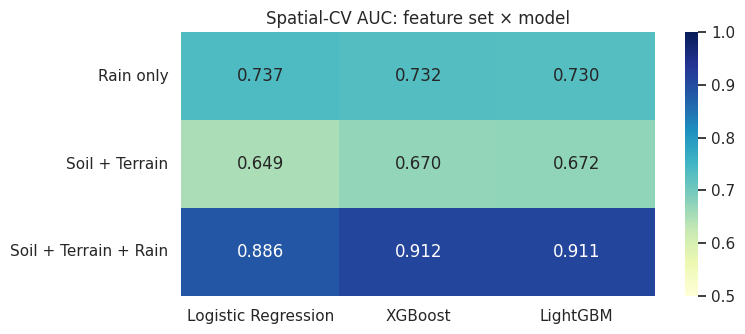

In [14]:
oof, rows = {}, []
for fs, feats in FEATURE_SETS.items():
    for m in MODELS:
        p = np.zeros(len(v3))
        for k in np.unique(folds):
            tr, te = folds != k, folds == k
            # Fill NaNs with 0 to handle the 3 rows missing rain data
            X_tr = v3.loc[tr, feats].fillna(0)
            X_te = v3.loc[te, feats].fillna(0)
            p[te] = make_model(m).fit(X_tr, y[tr]).predict_proba(X_te)[:, 1]
            rows.append(dict(feature_set=fs, model=m, fold=k, auc=roc_auc_score(y[te], p[te])))
        oof[(fs, m)] = p
pf = pd.DataFrame(rows)
summary = pf.groupby("feature_set", as_index=False).auc.agg(AUC_mean="mean", AUC_std="std").round(3)
summary = summary.sort_values("AUC_mean", ascending=False).reset_index(drop=True)
display(summary)

# Group and pivot to display heatmap properly
pivot_summary = pf.groupby(["feature_set","model"]).auc.agg(AUC_mean="mean").round(3).reset_index()
pivot = pivot_summary.pivot(index="feature_set", columns="model", values="AUC_mean")[MODELS]
plt.figure(figsize=(8, 3.5)); sns.heatmap(pivot, annot=True, fmt=".3f", cmap="YlGnBu", vmin=0.5, vmax=1)
plt.title("Spatial-CV AUC: feature set × model"); plt.ylabel(""); plt.xlabel(""); plt.tight_layout(); plt.show()

### Part 9: Spatial vs. Temporal Discrimination Capability
Quantifying how well our models perform at distinguishing landslide locations from other locations (Spatial: *where*) vs. identifying when landslide events happen compared to quiet days (Temporal: *when*).

In [15]:
def sl(mask, p): return roc_auc_score(y[mask], p[mask])
m_where = np.isin(rtype, ["event", "spatial_control"])   # landslide place vs OTHER place, same storm day
m_when  = np.isin(rtype, ["event", "temporal_control"])  # landslide place on landslide day vs SAME place on a quiet day
out = []
for fs in FEATURE_SETS:
    p = oof[(fs, "LightGBM")]
    out.append(dict(feature_set=fs, all_rows=sl(np.ones(len(y), bool), p),
                    where_other_place=sl(m_where, p), when_quiet_day=sl(m_when, p)))
pd.DataFrame(out).round(3)

,feature_set,all_rows,where_other_place,when_quiet_day
0,Soil + Terrain,0.661,0.823,0.500
1,Rain only,0.702,0.406,0.998
2,Soil + Terrain + Rain,0.906,0.820,0.993


### Part 10: Robustness Check Against Wet Quiet Days
Testing model performance specifically on the wettest 20% of temporal control days to ensure the model distinguishes genuine landslide triggers from heavy non-triggering rainfall.

In [16]:
quiet_rows = rtype == "temporal_control"
cut = v3.loc[quiet_rows, "rain_3d_mm"].quantile(0.80)           # wettest 20% of quiet days
wet = quiet_rows & (v3["rain_3d_mm"].values >= cut)
hard = (rtype == "event") | wet

print(f"wettest 20% of quiet days: rain_3d >= {cut:.1f} mm (n = {wet.sum()})")
print("median rain_3d  events:", round(v3.loc[rtype == 'event', 'rain_3d_mm'].median(), 1),
      "| wet quiet days:", round(v3.loc[wet, 'rain_3d_mm'].median(), 1))
print("share of events below that cut:", round((v3.loc[rtype == 'event', 'rain_3d_mm'] < cut).mean(), 2))
pd.DataFrame([dict(feature_set=fs, AUC_events_vs_wet_quiet_days=sl(hard, oof[(fs, "LightGBM")]))
              for fs in FEATURE_SETS]).round(3)

wettest 20% of quiet days: rain_3d >= 28.9 mm (n = 97)
median rain_3d  events: 286.8 | wet quiet days: 43.5
share of events below that cut: 0.01


,feature_set,AUC_events_vs_wet_quiet_days
0,Soil + Terrain,0.518
1,Rain only,0.998
2,Soil + Terrain + Rain,0.987


### Part 11: Sensitivity Analysis & Monotonicity Test
Analyzing individual sample curves to verify if predicted scores scale monotonically as simulated rainfall rises from dry to storm levels.

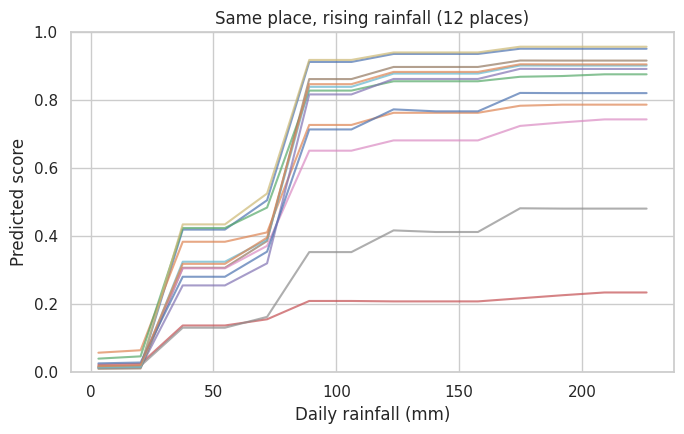

largest drop along any curve: 0.006 | curves with a drop above 0.05: 0 of 12


In [17]:
feats = SOIL + TERRAIN + RAIN
mdl = make_model("LightGBM").fit(v3[feats], y)
quiet_med = v3.loc[rtype == "temporal_control", RAIN].median()
storm_med = v3.loc[rtype == "event", RAIN].median()
places = v3[rtype == "event"].sample(12, random_state=1)
ts = np.linspace(0, 1.3, 14)
x_axis = quiet_med["rain_1d_mm"] + ts * (storm_med["rain_1d_mm"] - quiet_med["rain_1d_mm"])

plt.figure(figsize=(7, 4.5)); drops = []
for _, r in places.iterrows():
    rows = []
    for t in ts:
        row = r[SOIL + TERRAIN].copy()
        for c in RAIN: row[c] = quiet_med[c] + t * (storm_med[c] - quiet_med[c])
        row["rainfall_days_7d"] = round(row["rainfall_days_7d"])
        rows.append(row)
    p = mdl.predict_proba(pd.DataFrame(rows)[feats].astype(float))[:, 1]
    drops.append(float((np.maximum.accumulate(p) - p).max()))
    plt.plot(x_axis, p, alpha=0.7)
plt.xlabel("Daily rainfall (mm)"); plt.ylabel("Predicted score"); plt.ylim(0, 1)
plt.title("Same place, rising rainfall (12 places)"); plt.tight_layout(); plt.show()
print(f"largest drop along any curve: {max(drops):.3f} | curves with a drop above 0.05: {sum(d > 0.05 for d in drops)} of {len(drops)}")